# Task A — Rebuild nine time-series and share charts

Each left panel reproduces the analyst's recipe, not an endorsement of it.
Each right panel is an actually plotted redesign. The cells compute the
evidence from the supplied synthetic course data; the diagnosis below names
the mechanism rather than relying on generic objections.

**Sources:** `assignments/data/case01_...csv` through `case09_...csv`.
Charts use Matplotlib axes, explicit units, readable dates, and no dual y-axes.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd()
WEEK4_DIR = HERE if (HERE / "assignments" / "data").exists() else HERE / "week4"
ASSIGNMENTS_DIR = WEEK4_DIR / "assignments"
DATA_DIR = ASSIGNMENTS_DIR / "data"
sys.path.insert(0, str(ASSIGNMENTS_DIR))
from tslib import PALETTE, style_defaults, save_fig, audit_index

style_defaults()

from matplotlib.ticker import MaxNLocator

def monthly_index(values):
    return pd.to_datetime(values, format="%Y-%m")

def paired_axes(case_number, title):
    if case_number == 9:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
    else:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
    fig.suptitle(f"Case {case_number}: {title}", fontsize=14, fontweight="bold")
    return fig, axes

def show_pair(fig):
    plt.show()
    plt.close(fig)

## Case 1 — String-sorted months create a false annual cycle

Rows: 24 | largest drops in string-sorted recipe: [978, 958]
String-sorted sequence: ['2024-1', '2024-10', '2024-11', '2024-12', '2024-2'] ... ['2025-7', '2025-8', '2025-9']


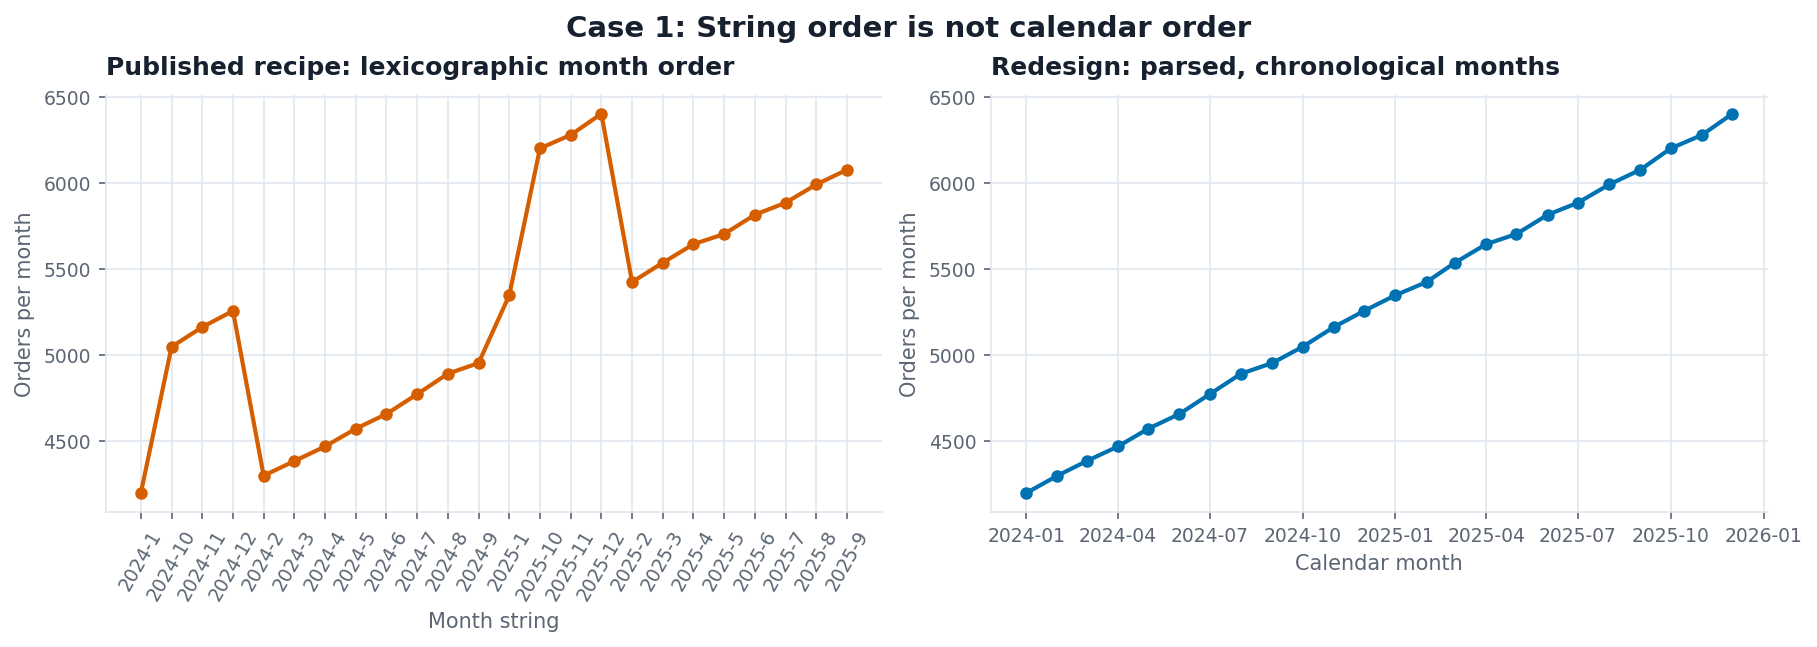

In [2]:
df = pd.read_csv(DATA_DIR / "case01_orders_stringdate.csv")
fig, ax = paired_axes(1, "String order is not calendar order")
wrong = df.sort_values("month")
ax[0].plot(wrong["month"], wrong["orders"], marker="o", color=PALETTE["highlight"])
ax[0].set(title="Published recipe: lexicographic month order", ylabel="Orders per month", xlabel="Month string")
ax[0].tick_params(axis="x", rotation=60)

right = df.assign(month_dt=monthly_index(df["month"])).sort_values("month_dt")
ax[1].plot(right["month_dt"], right["orders"], marker="o", color=PALETTE["series"][0])
ax[1].set(title="Redesign: parsed, chronological months", ylabel="Orders per month", xlabel="Calendar month")
fig.canvas.draw()
diffs = wrong["orders"].diff().dropna()
print("Rows:", len(df), "| largest drops in string-sorted recipe:", sorted(diffs[diffs < 0].abs().astype(int).tolist(), reverse=True)[:2])
print("String-sorted sequence:", wrong["month"].head(5).tolist(), "...", wrong["month"].tail(3).tolist())
show_pair(fig)

**Diagnosis.** The decoy is the apparent seasonal collapse; the y-axis starts
at zero as required, and all 24 rows are present. The mechanism is
lexicographic sorting of non-zero-padded `YYYY-M` strings: October–December
are placed beside January before February–September. Parse to dates first,
then sort by time. The redesign shows the actual chronological pattern.

## Case 2 — Row number hides the unrecorded calendar days

Recorded rows: 69 | elapsed calendar days: 90 | absent dates: 21
Recipe endpoints: 207 to 253 (+22.2%)


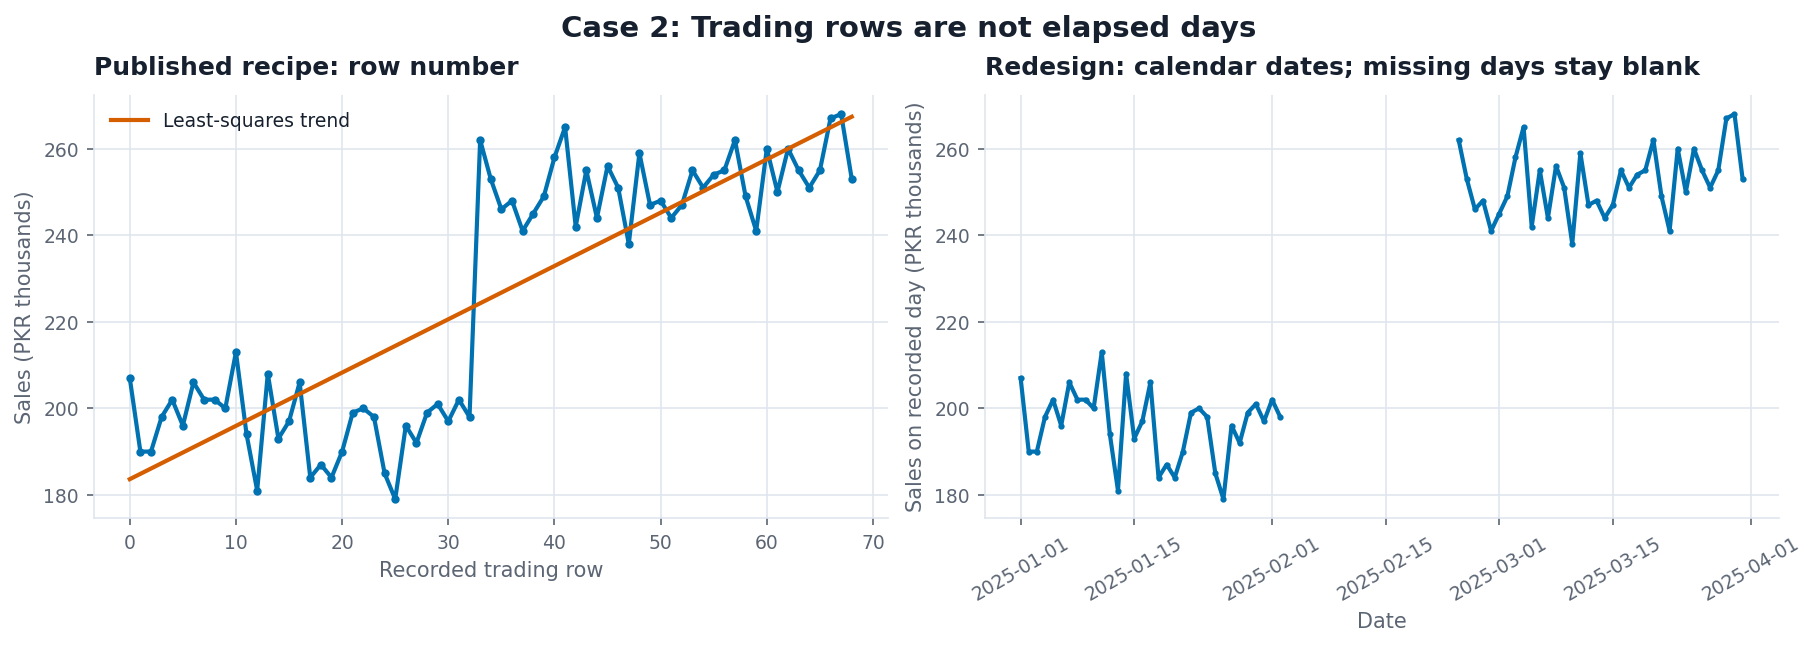

In [3]:
df = pd.read_csv(DATA_DIR / "case02_shop_closed.csv")
dates = pd.to_datetime(df["date"])
ordered = df.assign(date_dt=dates).sort_values("date_dt")
row_x = np.arange(len(df))
coef = np.polyfit(row_x, df["sales_pkr_k"], 1)
fit = np.polyval(coef, row_x)
fig, ax = paired_axes(2, "Trading rows are not elapsed days")
ax[0].plot(row_x, df["sales_pkr_k"], marker="o", ms=3, color=PALETTE["series"][0])
ax[0].plot(row_x, fit, color=PALETTE["highlight"], label="Least-squares trend")
ax[0].set(title="Published recipe: row number", xlabel="Recorded trading row", ylabel="Sales (PKR thousands)")
ax[0].legend()

calendar = ordered.set_index("date_dt")["sales_pkr_k"].asfreq("D")
ax[1].plot(calendar.index, calendar, marker=".", ms=4, color=PALETTE["series"][0])
ax[1].set(title="Redesign: calendar dates; missing days stay blank", xlabel="Date", ylabel="Sales on recorded day (PKR thousands)")
ax[1].tick_params(axis="x", rotation=30)
print("Recorded rows:", len(df), "| elapsed calendar days:", (dates.max() - dates.min()).days + 1,
      "| absent dates:", len(pd.date_range(dates.min(), dates.max(), freq="D").difference(pd.DatetimeIndex(dates))))
print(f"Recipe endpoints: {df.sales_pkr_k.iloc[0]} to {df.sales_pkr_k.iloc[-1]} (+{(df.sales_pkr_k.iloc[-1] / df.sales_pkr_k.iloc[0] - 1) * 100:.1f}%)")
show_pair(fig)

**Diagnosis.** The decoy is that the endpoint increase really is about 22%;
that does not establish steady growth per calendar day. The x-axis compresses
all unrecorded non-trading days, so equal horizontal steps mean successive
rows, not equal elapsed time. The redesign uses the date index and leaves
unrecorded dates as gaps rather than inventing sales.

## Case 3 — Summing a level fabricates a July step

Daily-sum means: 8782.4 June; 12543.1 July
Hourly level means: 534.4 June; 522.6 July


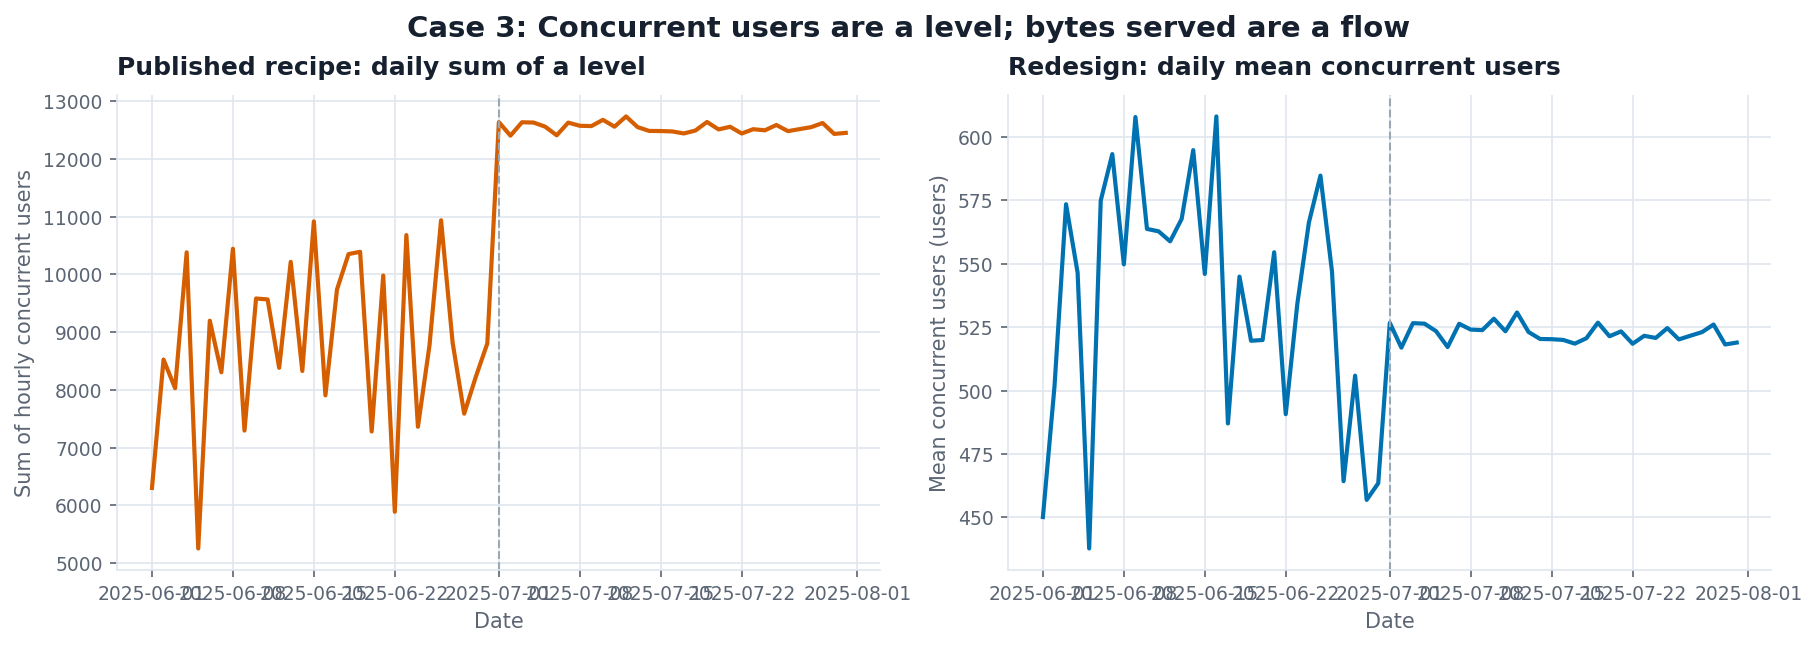

In [4]:
df = pd.read_csv(DATA_DIR / "case03_bandwidth_levels.csv", parse_dates=["ts"]).set_index("ts").sort_index()
users = df["concurrent_users"]
daily_sum = users.resample("D").sum()
daily_mean = users.resample("D").mean()
fig, ax = paired_axes(3, "Concurrent users are a level; bytes served are a flow")
ax[0].plot(daily_sum.index, daily_sum, color=PALETTE["highlight"])
ax[0].set(title="Published recipe: daily sum of a level", xlabel="Date", ylabel="Sum of hourly concurrent users")
ax[1].plot(daily_mean.index, daily_mean, color=PALETTE["series"][0])
ax[1].set(title="Redesign: daily mean concurrent users", xlabel="Date", ylabel="Mean concurrent users (users)")
for a in ax:
    a.axvline(pd.Timestamp("2025-07-01"), color=PALETTE["muted"], ls="--", lw=1)
means = users.groupby(users.index.to_period("M")).mean()
print("Daily-sum means:", daily_sum.loc["2025-06"].mean().round(1), "June;",
      daily_sum.loc["2025-07"].mean().round(1), "July")
print("Hourly level means:", means.loc["2025-06"].round(1), "June;",
      means.loc["2025-07"].round(1), "July")
show_pair(fig)

**Diagnosis.** The decoy is a real change in concurrent users around July;
it is not evidence of a 43% instantaneous jump. `concurrent_users` is a
level (users present at an instant), so summing the 24 hourly readings
multiplies the level by the number of observations. Aggregate it by mean (or
another explicitly justified level statistic). `bytes_served`, by contrast,
is a flow and is correctly summed over time.

## Case 4 — A trailing mean reports the turning point late

Trailing minimum: 2025-09-07 00:00:00 | centred minimum: 2025-08-23 00:00:00 | lag (days): 15 | half-window: 15


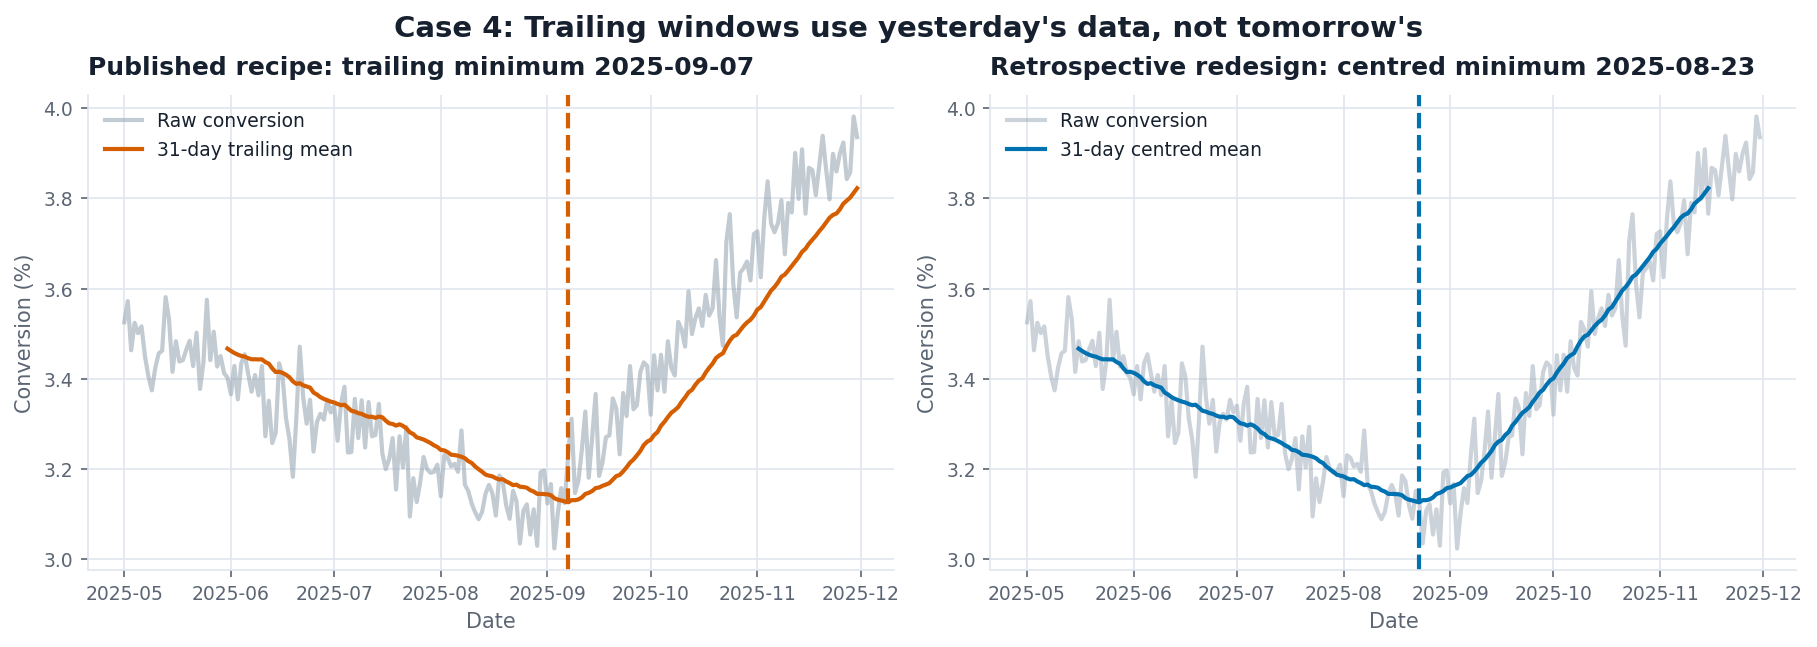

In [5]:
df = pd.read_csv(DATA_DIR / "case04_intervention_lag.csv", parse_dates=["date"]).set_index("date").sort_index()
s = df["conversion_pct"]
trailing = s.rolling(31, min_periods=31).mean()
centered = s.rolling(31, center=True, min_periods=31).mean()
fig, ax = paired_axes(4, "Trailing windows use yesterday's data, not tomorrow's")
ax[0].plot(s.index, s, color=PALETTE["muted"], alpha=.6, label="Raw conversion")
ax[0].plot(trailing.index, trailing, color=PALETTE["highlight"], label="31-day trailing mean")
ax[0].axvline(trailing.idxmin(), color=PALETTE["highlight"], ls="--")
ax[0].set(title=f"Published recipe: trailing minimum {trailing.idxmin():%Y-%m-%d}", xlabel="Date", ylabel="Conversion (%)")
ax[0].legend()
ax[1].plot(s.index, s, color=PALETTE["muted"], alpha=.5, label="Raw conversion")
ax[1].plot(centered.index, centered, color=PALETTE["series"][0], label="31-day centred mean")
ax[1].axvline(centered.idxmin(), color=PALETTE["series"][0], ls="--")
ax[1].set(title=f"Retrospective redesign: centred minimum {centered.idxmin():%Y-%m-%d}", xlabel="Date", ylabel="Conversion (%)")
ax[1].legend()
print("Trailing minimum:", trailing.idxmin(), "| centred minimum:", centered.idxmin(),
      "| lag (days):", (trailing.idxmin() - centered.idxmin()).days,
      "| half-window:", 31 // 2)
show_pair(fig)

**Diagnosis.** The decoy is that the new checkout could still have helped;
this chart alone does not identify causation. The demonstrated mechanism is
window alignment: a 31-day trailing mean includes 30 prior days, so its
minimum is delayed relative to a centred estimate. The redesign retains the
raw series and labels the centred window; a live dashboard must use a
trailing window and say so in its caption.

## Case 5 — A seasonal peak-to-trough slice is not a six-month trend

Selected n: 7 | selected endpoints: 158.8 to 92.2 | change: -41.9%
All months: 36 | same-month year-over-year changes (2025 vs 2024):


,YoY change (%)
m,
1,13.3
2,6.8
3,8.8
4,8.7
5,7.7
6,11.5
7,10.1
8,12.9
9,12.9


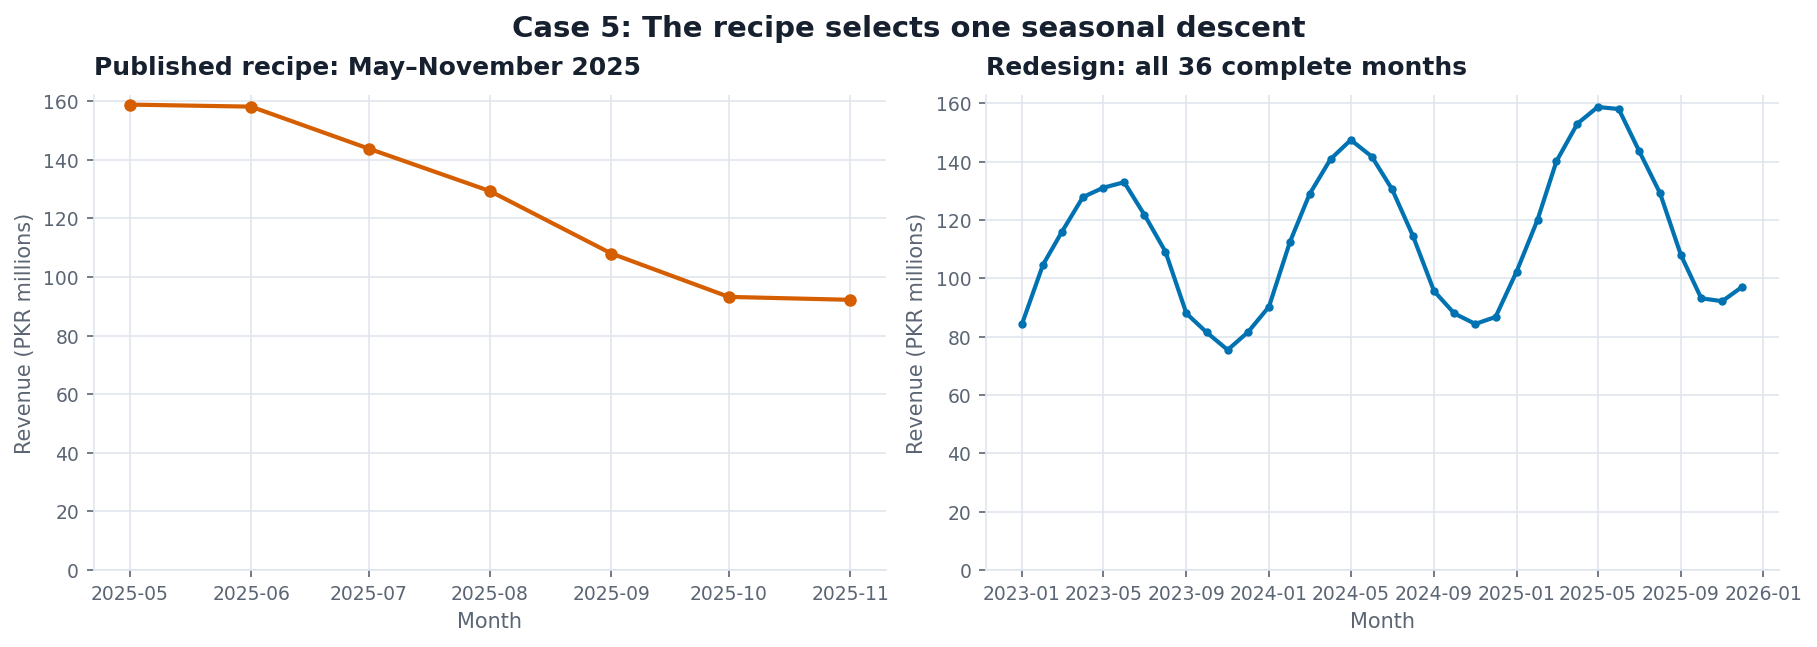

In [6]:
df = pd.read_csv(DATA_DIR / "case05_revenue_window.csv")
df["month_dt"] = monthly_index(df["month"])
selected = df[df["month"].between("2025-05", "2025-11")]
fig, ax = paired_axes(5, "The recipe selects one seasonal descent")
ax[0].plot(selected.month_dt, selected.revenue_pkr_m, marker="o", color=PALETTE["highlight"])
ax[0].set_ylim(bottom=0)
ax[0].set(title="Published recipe: May–November 2025", xlabel="Month", ylabel="Revenue (PKR millions)")
ax[1].plot(df.month_dt, df.revenue_pkr_m, marker="o", ms=3, color=PALETTE["series"][0])
ax[1].set_ylim(bottom=0)
ax[1].set(title="Redesign: all 36 complete months", xlabel="Month", ylabel="Revenue (PKR millions)")
print("Selected n:", len(selected), "| selected endpoints:", selected.revenue_pkr_m.iloc[0], "to", selected.revenue_pkr_m.iloc[-1],
      "| change:", f"{(selected.revenue_pkr_m.iloc[-1] / selected.revenue_pkr_m.iloc[0] - 1) * 100:.1f}%")
print("All months:", len(df), "| same-month year-over-year changes (2025 vs 2024):")
compare = df.assign(year=df.month_dt.dt.year, m=df.month_dt.dt.month).pivot(index="m", columns="year", values="revenue_pkr_m")
display(((compare[2025] / compare[2024] - 1) * 100).round(1).rename("YoY change (%)").to_frame())
show_pair(fig)

**Diagnosis.** The decoy is the truncated-axis objection: both axes start
at zero. The sample is seven points, not a tiny-n error relative to the
recipe. The mechanism is selecting May–November, a peak-to-trough portion of
a strongly seasonal series, and calling that chosen phase a persistent
trend. Show the full 36-month context and compare like months year over year.

## Case 6 — October is an incomplete month

            orders  days_recorded  days_in_month  complete
2025-08-01   11042             31             31      True
2025-09-01   10805             30             30      True
2025-10-01    4041             11             31     False


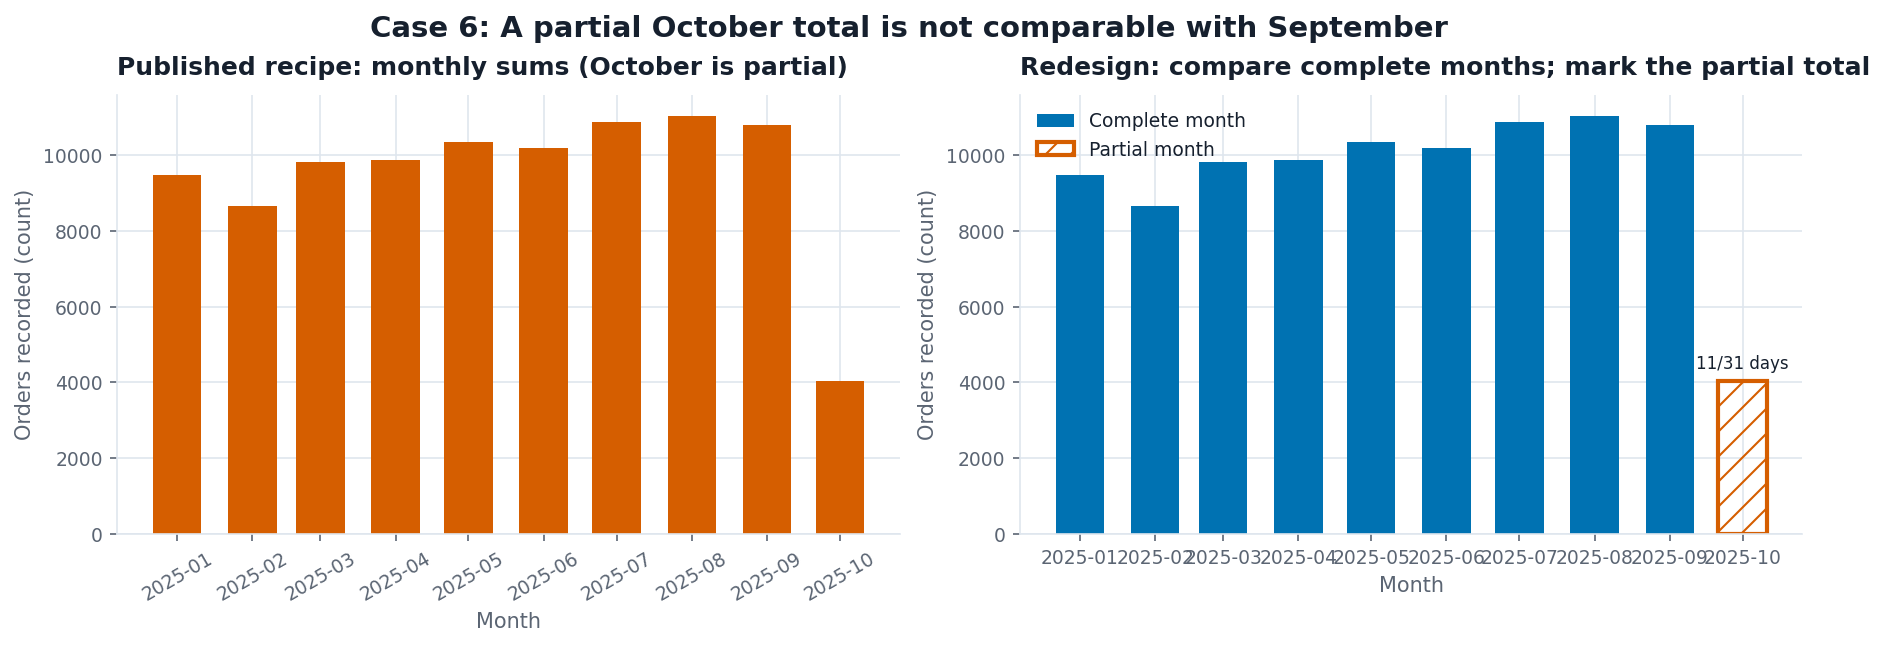

In [7]:
df = pd.read_csv(DATA_DIR / "case06_monthly_partial.csv", parse_dates=["date"]).set_index("date").sort_index()
monthly = df["orders"].resample("MS").sum()
days = df["orders"].resample("MS").count()
expected_days = pd.Series({d: d.days_in_month for d in monthly.index}, dtype=float)
complete = days.eq(expected_days)
fig, ax = paired_axes(6, "A partial October total is not comparable with September")
ax[0].bar(monthly.index, monthly.values, width=20, color=PALETTE["highlight"])
ax[0].set(title="Published recipe: monthly sums (October is partial)", xlabel="Month", ylabel="Orders recorded (count)")
ax[0].tick_params(axis="x", rotation=30)
full = monthly[complete]
ax[1].bar(full.index, full.values, width=20, color=PALETTE["series"][0], label="Complete month")
partial = monthly[~complete]
if len(partial):
    ax[1].bar(partial.index, partial.values, width=20, facecolor="none", edgecolor=PALETTE["highlight"],
              linewidth=2, hatch="//", label="Partial month")
    for date, value in partial.items():
        ax[1].annotate(f"{int(days.loc[date])}/{date.days_in_month} days",
                       (date, value), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8)
ax[1].set(title="Redesign: compare complete months; mark the partial total", xlabel="Month", ylabel="Orders recorded (count)")
ax[1].legend()
print(pd.DataFrame({"orders": monthly.astype(int), "days_recorded": days,
                    "days_in_month": expected_days.astype(int), "complete": complete}).tail(3))
show_pair(fig)

**Diagnosis.** The decoy is the zero baseline: it is correct for these bars.
The mechanism is an incomplete final period: the October extract covers
fewer days than September, so its sum is not a like-for-like monthly total.
The redesign keeps the observed October total visible but marks it as
partial and does not compare it as a complete month.

## Case 7 — A stacked area changes the baseline underneath Product D

Total envelope: 548.3 to 708.7 PKR m
Product D range: 94.0 to 106.3 | Product D coefficient of variation: 0.035
All product-level coefficient of variation: {'product_a': 0.065, 'product_b': 0.234, 'product_c': 0.052, 'product_d': 0.035}


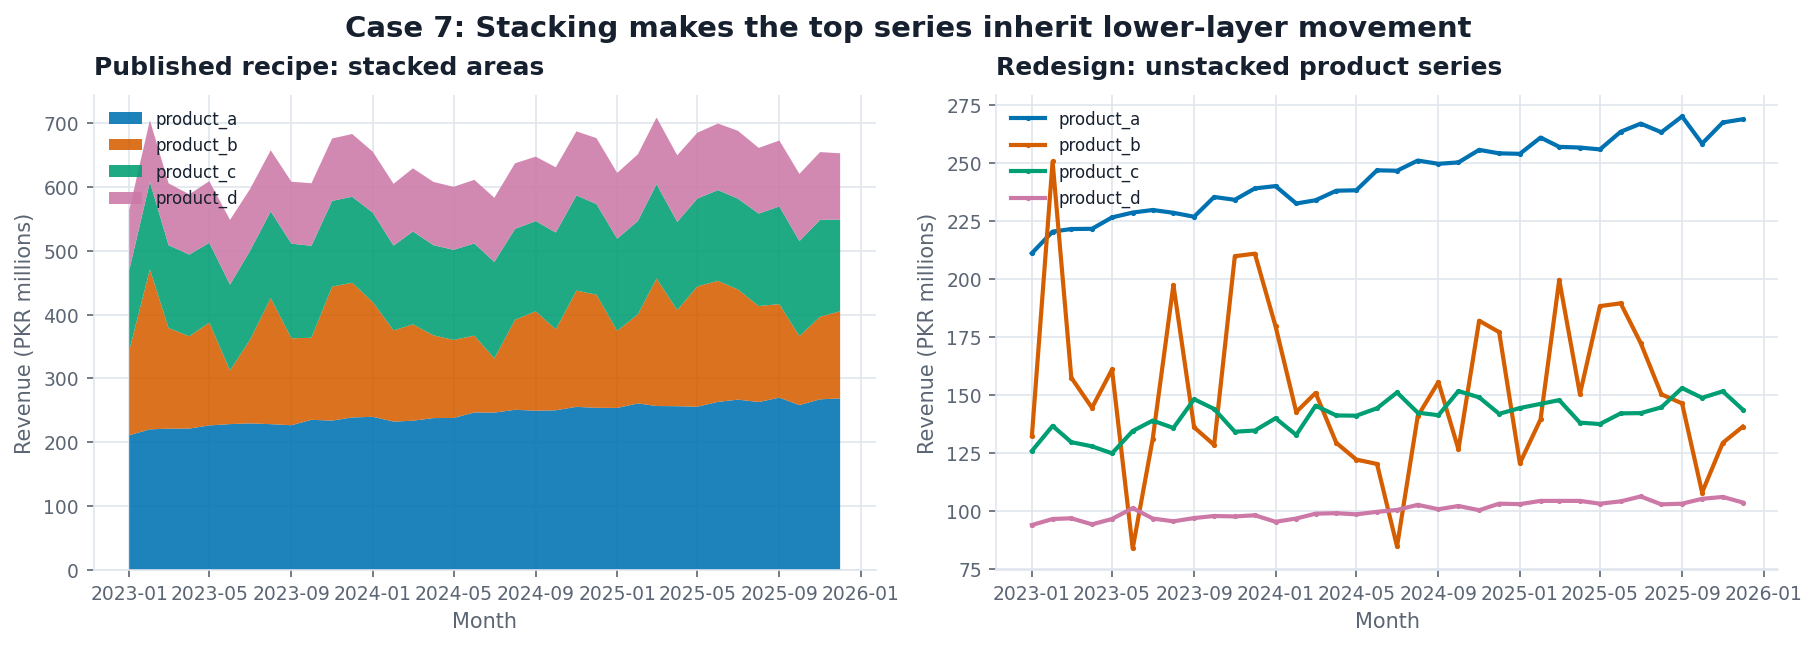

In [8]:
df = pd.read_csv(DATA_DIR / "case07_stacked_products.csv")
dates = monthly_index(df["month"])
cols = [c for c in df.columns if c.startswith("product_")]
fig, ax = paired_axes(7, "Stacking makes the top series inherit lower-layer movement")
ax[0].stackplot(dates, *[df[c].to_numpy() for c in cols], labels=cols,
                colors=PALETTE["series"] + [PALETTE["series_4th"]], alpha=.88)
ax[0].set(title="Published recipe: stacked areas", xlabel="Month", ylabel="Revenue (PKR millions)")
ax[0].legend(loc="upper left", fontsize=8)
for i, col in enumerate(cols):
    ax[1].plot(dates, df[col], marker=".", ms=3, label=col,
               color=(PALETTE["series"] + [PALETTE["series_4th"]])[i])
ax[1].set(title="Redesign: unstacked product series", xlabel="Month", ylabel="Revenue (PKR millions)")
ax[1].legend(loc="upper left", fontsize=8)
totals = df[cols].sum(axis=1)
print("Total envelope:", round(totals.min(), 1), "to", round(totals.max(), 1), "PKR m")
print("Product D range:", round(df.product_d.min(), 1), "to", round(df.product_d.max(), 1),
      "| Product D coefficient of variation:", round(df.product_d.std() / df.product_d.mean(), 3))
print("All product-level coefficient of variation:", df[cols].std().div(df[cols].mean()).round(3).to_dict())
show_pair(fig)

**Diagnosis.** The decoy is that the total business changes; the overall
envelope is stable enough to check that directly. The mechanism is the
moving cumulative baseline of a stacked area: Product D's top boundary is
the sum of D and all products below it, so volatility in lower layers
changes its apparent height. Unstacking (or faceting) restores a common zero
baseline for each product.

## Case 8 — Multi-touch attribution categories overlap

Exclusivity audit: {'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}


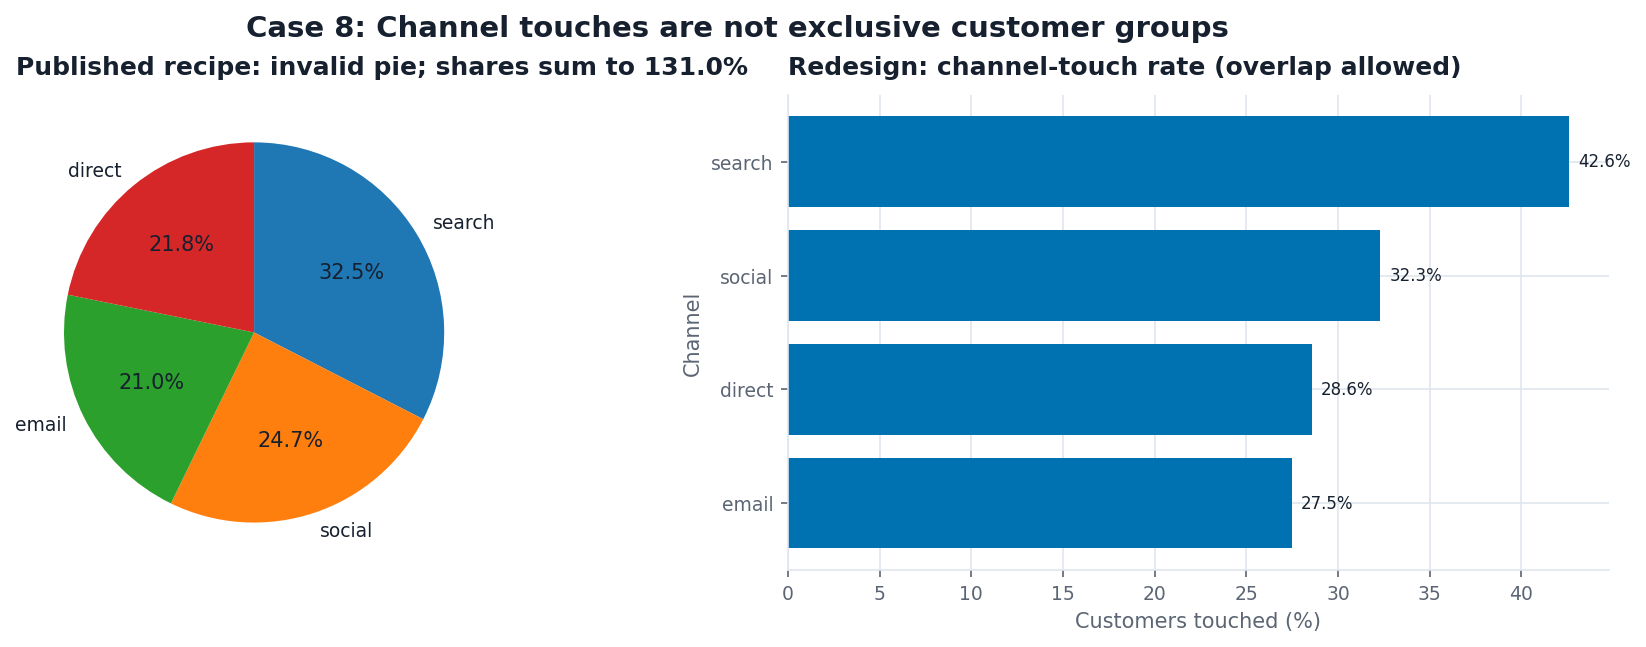

In [9]:
from tslib import exclusivity_check
df = pd.read_csv(DATA_DIR / "case08_channel_attrib.csv")
flags = [c for c in df.columns if c.startswith("touch_")]
check = exclusivity_check(df, flags)
shares = df[flags].mean().mul(100).sort_values(ascending=False)
fig, ax = paired_axes(8, "Channel touches are not exclusive customer groups")
ax[0].pie(shares.reindex(flags).values, labels=[c.replace("touch_", "") for c in flags],
          startangle=90, counterclock=False, autopct="%1.1f%%")
ax[0].set_title(f"Published recipe: invalid pie; shares sum to {shares.sum():.1f}%")
ax[1].barh([x.replace("touch_", "") for x in shares.index[::-1]], shares.values[::-1],
           color=PALETTE["series"][0])
ax[1].set(title="Redesign: channel-touch rate (overlap allowed)", xlabel="Customers touched (%)",
          ylabel="Channel")
for i, val in enumerate(shares.values[::-1]):
    ax[1].text(val + .5, i, f"{val:.1f}%", va="center", fontsize=8)
print("Exclusivity audit:", check)
show_pair(fig)

**Diagnosis.** The decoy is that each rate has the same customer denominator;
that does not make the channel parts disjoint. Customers can touch multiple
channels, and the four shares sum above 100%, so a pie normalizes categories
that do not partition the whole. The horizontal bars retain the meaningful
per-channel rate and explicitly state that overlap is allowed.

## Case 9 — A ratio rises while its denominator falls

,quarter,total_revenue_pkr_m,premium_revenue_pkr_m,share_pct
4,2025Q1,745.0,227.2,30.5
5,2025Q2,700.0,227.5,32.5
6,2025Q3,650.0,228.8,35.2
7,2025Q4,600.0,228.0,38.0


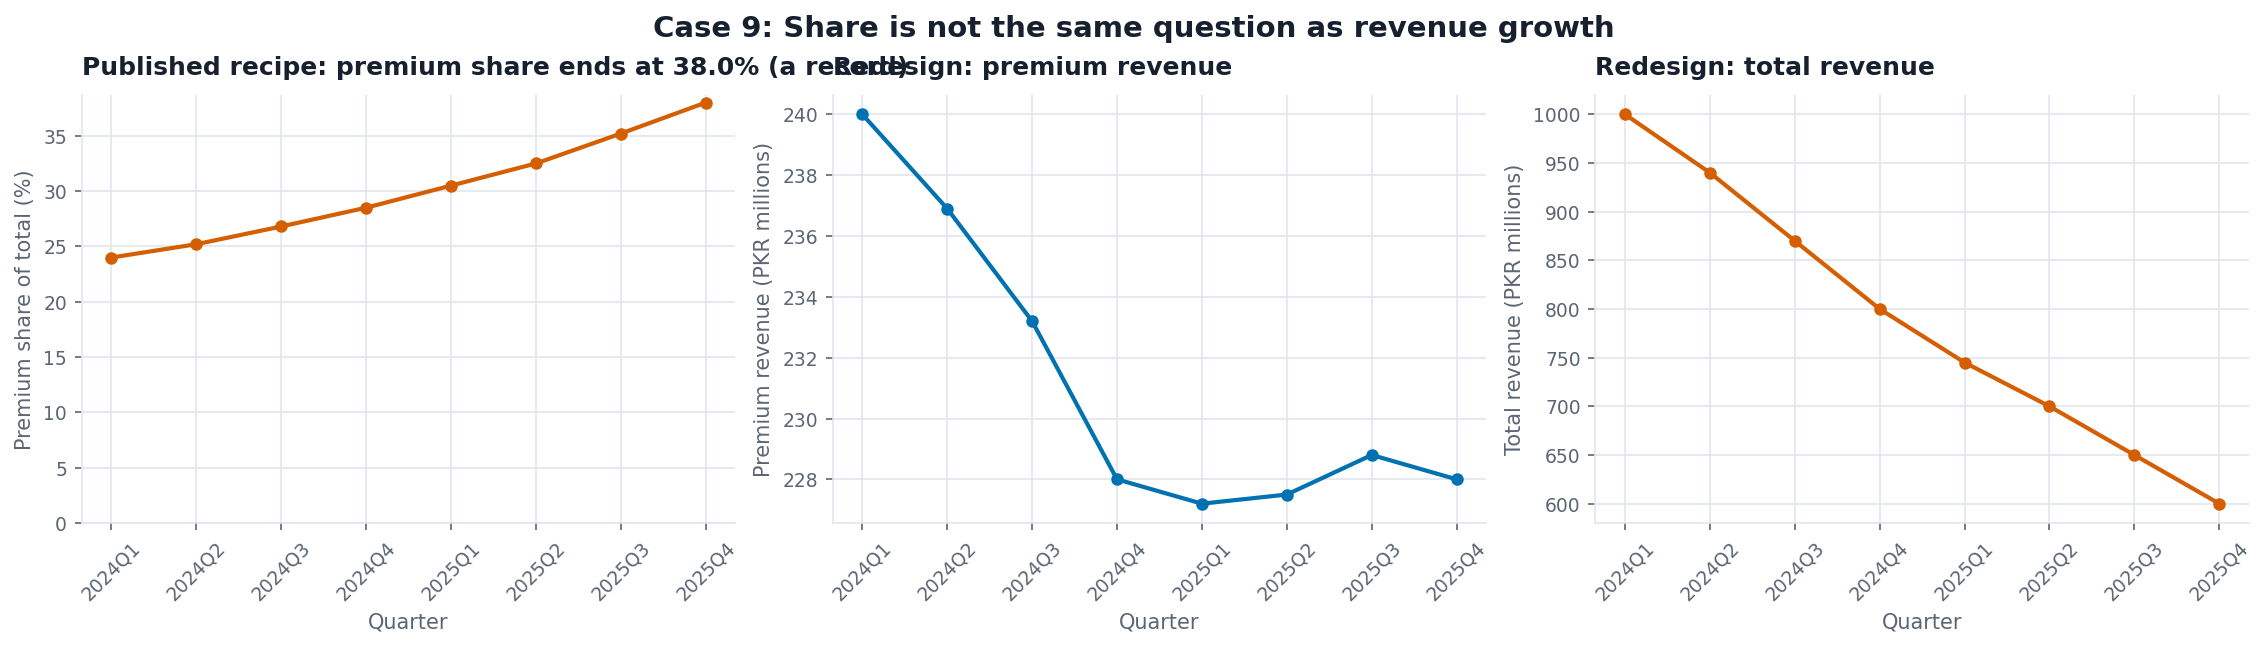

In [10]:
df = pd.read_csv(DATA_DIR / "case09_premium_share.csv")
df["share_pct"] = df.premium_revenue_pkr_m / df.total_revenue_pkr_m * 100
df["other_revenue_pkr_m"] = df.total_revenue_pkr_m - df.premium_revenue_pkr_m
fig, ax = paired_axes(9, "Share is not the same question as revenue growth")
ax[0].plot(df.quarter, df.share_pct, marker="o", color=PALETTE["highlight"])
ax[0].set_ylim(bottom=0)
ax[0].set(title=f"Published recipe: premium share ends at {df.share_pct.iloc[-1]:.1f}% (a record)",
          xlabel="Quarter", ylabel="Premium share of total (%)")
ax[0].tick_params(axis="x", rotation=45)
ax[1].plot(df.quarter, df.premium_revenue_pkr_m, marker="o", color=PALETTE["series"][0])
ax[1].set(title="Redesign: premium revenue", xlabel="Quarter", ylabel="Premium revenue (PKR millions)")
ax[1].tick_params(axis="x", rotation=45)
ax[2].plot(df.quarter, df.total_revenue_pkr_m, marker="o", color=PALETTE["series"][1])
ax[2].set(title="Redesign: total revenue", xlabel="Quarter", ylabel="Total revenue (PKR millions)")
ax[2].tick_params(axis="x", rotation=45)
display(df[["quarter", "total_revenue_pkr_m", "premium_revenue_pkr_m", "share_pct"]].tail(4).round(1))
show_pair(fig)

**Diagnosis.** The premium share increase is arithmetically true; the decoy
is interpreting a higher ratio as rising premium sales. The mechanism is a
denominator effect: the premium share can rise when total revenue falls
faster than premium revenue (or while premium revenue itself declines).
Separate, zero-baseline panels show the numerator and denominator without a
dual y-axis.

## Evidence checklist

The nine rebuilds and nine redesigned views above are generated from the
recipes. Read the printed checks beside each figure before accepting the
diagnosis. In particular, case 3 distinguishes a **level** from a **flow**;
case 8 tests exclusivity numerically; and case 9 separates a ratio from its
components. All quoted data are synthetic course data, not real business
results.